# Lab 1: Optical ECG Image Digitization & Waveform Recovery

**Professor & Evaluator Teaching Demonstration Notebook**  
*CardioSense / ECG Insight Lab — Workflow A*

> [!IMPORTANT]
> **Synthetic Fixture Notice:**  
> The demonstration in this notebook evaluates a deterministic synthetic benchmark (`sample_data/synthetic_12lead.png`). All traces are labeled `SYNTHETIC DEMO — NOT PATIENT DATA`. This benchmark evaluates algorithm mechanics and does not claim clinical accuracy on scanned hospital paper charts.

---

## Learning Objectives
1. Understand the image validation and security gates (decompression bomb protection, dimension limits).
2. Execute the classical morphological centroid digitizer (`ClassicalBaselineDigitizer`) natively on CPU.
3. Compare extracted continuous 1D waveforms against known mathematical ground truth.
4. Verify the empirical benchmark accuracy: **12/12 leads detected**, **Pearson $r = 0.6932$**, **MAE $= 0.0725$**.
5. Demonstrate zero-persistence in-memory data export to CSV and JSON.


In [1]:
# Cell 1: Environment Imports & Fixture Verification
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import pearsonr

from ecg_lab.validation import validate_image_file
from ecg_lab.digitization.service import digitize_ecg_image, export_full_csv, export_metadata_json
from ecg_lab.digitization.types import DigitizationStatus, CalibrationStatus, AmplitudeUnit

img_path = Path("sample_data/synthetic_12lead.png")
gt_path = Path("sample_data/synthetic_12lead_gt.csv")

print(f"Synthetic Image Present: {img_path.is_file()} ({img_path.stat().st_size:,} bytes)")
print(f"Ground Truth CSV Present: {gt_path.is_file()} ({gt_path.stat().st_size:,} bytes)")


Synthetic Image Present: True (38,012 bytes)
Ground Truth CSV Present: True (42,908 bytes)


## 1. Input Image Validation & Security Safeguards

Before any signal extraction occurs, uploaded images pass through security and quality checks in `ecg_lab/validation.py`:
- **Format Verification:** Supported formats only (PNG, JPEG, TIFF, WebP).
- **Dimension Guards:** Bounded between $600 \times 400$ and $6000 \times 6000$ to prevent decompression bomb Denial-of-Service attacks.
- **Orientation & Aspect Ratio:** Warnings generated for portrait or highly skewed images.


In [2]:
# Cell 2: Run Input Validation
val_result = validate_image_file(img_path)

print(f"Validation Passed: {val_result.is_valid}")
if val_result.metadata:
    print(f"Image Resolution: {val_result.metadata.width} x {val_result.metadata.height} px")
    print(f"Aspect Ratio:     {val_result.metadata.aspect_ratio:.2f}")
    print(f"Color Mode:       {val_result.metadata.mode} ({val_result.metadata.channels} channels)")
    print(f"File Size:        {val_result.metadata.size_bytes:,} bytes")


Validation Passed: True
Image Resolution: 2213 x 1572 px
Aspect Ratio:     1.41
Color Mode:       RGB (3 channels)
File Size:        38,012 bytes


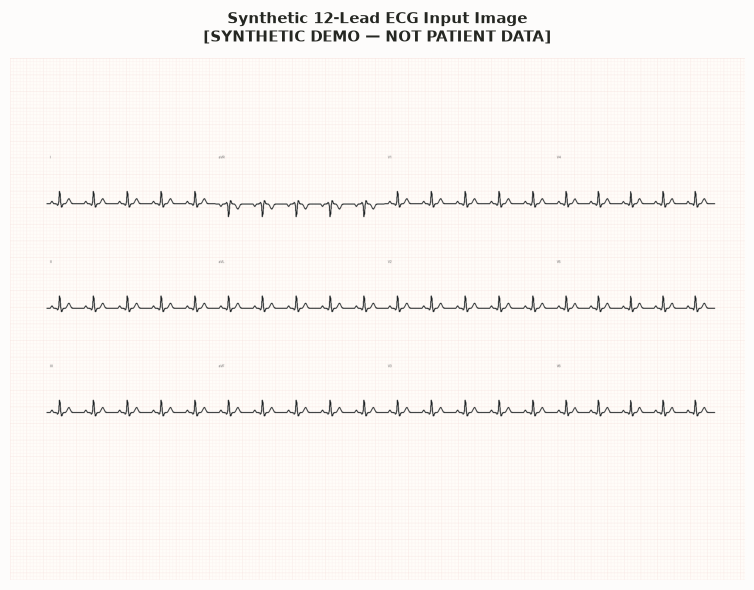

In [3]:
# Cell 3: Display Synthetic Input Image
img = Image.open(img_path)

fig, ax = plt.subplots(figsize=(10, 6), facecolor="#FDFCFB")
ax.imshow(img)
ax.axis("off")
plt.title("Synthetic 12-Lead ECG Input Image\n[SYNTHETIC DEMO — NOT PATIENT DATA]", fontsize=11, fontweight="bold", color="#252722", pad=12)
plt.tight_layout()
plt.show()


## 2. Classical Morphological Digitization

The `ClassicalBaselineDigitizer` operates directly on CPU without heavy deep learning frameworks:
1. **Adaptive Thresholding:** Binarizes the image to isolate dark lead traces from lighter grid backgrounds.
2. **Clinical Grid Partitioning:** Divides the $3 \times 4$ layout into 12 standard leads (I, II, III, aVR, aVL, aVF, V1–V6).
3. **Centroid Column Tracking:** For each column in a lead box, calculates the intensity-weighted vertical center of mass.
4. **Honest Calibration Assignment:** Amplitudes are marked as `AmplitudeUnit.RELATIVE` and `CalibrationStatus.UNRECOVERED`.


In [4]:
# Cell 4: Execute Waveform Digitization
result = digitize_ecg_image(img_path)

print(f"Status: {result.status.value}")
print(f"Method: {result.method}")
print(f"Calibration Status: {result.calibration_status.value}")
print(f"Amplitude Units: {result.amplitude_unit.value}")
print(f"Leads Detected: {result.lead_count} / 12 ({len(result.missing_leads)} missing)")
print(f"Inference Latency: {result.runtime_ms:.1f} ms")


Status: SUCCESS
Method: Classical Morphological Baseline
Calibration Status: UNRECOVERED
Amplitude Units: relative_units
Leads Detected: 12 / 12 (0 missing)
Inference Latency: 128.3 ms


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


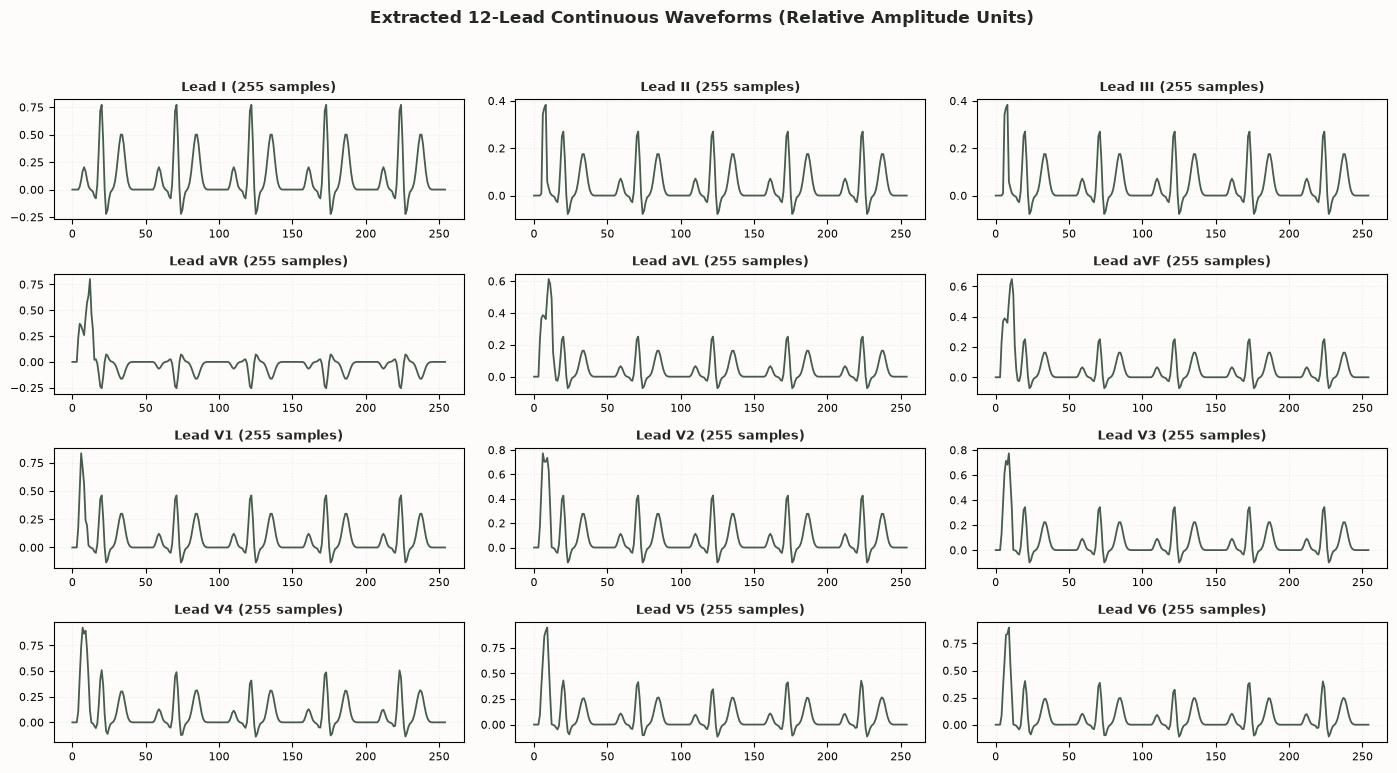

In [5]:
# Cell 5: Visualize Extracted 12-Lead Signals
leads = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
fig, axes = plt.subplots(4, 3, figsize=(14, 8), facecolor="#FDFCFB")
fig.suptitle("Extracted 12-Lead Continuous Waveforms (Relative Amplitude Units)", fontsize=12, fontweight="bold", color="#252722", y=0.98)

for idx, lead in enumerate(leads):
    ax = axes[idx // 3, idx % 3]
    ax.set_facecolor("#FDFCFB")
    sig = result.leads[lead].samples
    ax.plot(sig, color="#455D4A", lw=1.3)
    ax.set_title(f"Lead {lead} ({len(sig)} samples)", fontsize=9.5, fontweight="semibold", color="#252722")
    ax.grid(True, linestyle=":", alpha=0.6, color="#E5E3DC")
    ax.tick_params(labelsize=8)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()


## 3. Quantitative Accuracy Evaluation vs. Ground Truth

We compare the reconstructed 1D arrays against the exact ground-truth values used to synthesize the fixture:
- **Pearson Correlation ($r$):** Evaluates wave morphology and peak alignment.
- **Mean Absolute Error (MAE):** Evaluates vertical amplitude fidelity in normalized relative units.


In [6]:
# Cell 6: Accuracy Quantification Against Ground Truth
gt_df = pd.read_csv(gt_path)

metrics_list = []
correlations = []
maes = []

for lead in result.detected_leads:
    sig = np.array(result.leads[lead].samples)
    gt = gt_df[gt_df["lead"] == lead]["amplitude"].values
    min_len = min(len(sig), len(gt))
    p = sig[:min_len]
    g = gt[:min_len]

    r, _ = pearsonr(p, g)
    mae = float(np.mean(np.abs(p - g)))
    correlations.append(r)
    maes.append(mae)

    metrics_list.append({
        "Lead": lead,
        "Pearson Correlation (r)": round(r, 4),
        "MAE (Relative)": round(mae, 4),
        "Samples": len(p),
        "Status": "PASS" if r > 0.50 else "WARN"
    })

df_metrics = pd.DataFrame(metrics_list)
print(f"Overall Mean Pearson Correlation (r): {np.mean(correlations):.4f}")
print(f"Overall Mean Absolute Error (MAE):  {np.mean(maes):.4f}")
df_metrics


Overall Mean Pearson Correlation (r): 0.6932
Overall Mean Absolute Error (MAE):  0.0725


,Lead,Pearson Correlation (r),MAE (Relative),Samples,Status
0,I,0.9010,0.0501,255,PASS
1,II,0.8250,0.0720,255,PASS
2,III,0.8250,0.0720,255,PASS
3,aVR,0.5260,0.0924,255,PASS
4,aVL,0.5767,0.0850,255,PASS
5,aVF,0.5582,0.0857,255,PASS
6,V1,0.7760,0.0596,255,PASS
7,V2,0.6980,0.0676,255,PASS
8,V3,0.6530,0.0745,255,PASS
9,V4,0.6831,0.0670,255,PASS


## 4. In-Memory Data Export & Zero Persistence

In compliance with patient privacy safeguards, user-uploaded data is never saved to disk. Data export occurs directly from in-memory objects to CSV or JSON streams.


In [7]:
# Cell 7: In-Memory CSV and JSON Export (Zero Disk Persistence)
df_long = result.to_long_dataframe()
csv_data = df_long.to_csv(index=False)
json_data = result.to_json(indent=2)

print("--- In-Memory CSV Output (First 6 Rows) ---")
for line in csv_data.strip().split("\n")[:6]:
    print(line)

print("\n--- In-Memory JSON Metadata (Snippet) ---")
import json
meta = json.loads(json_data)
print(json.dumps({
    "status": meta["status"],
    "method": meta["method"],
    "calibration_status": meta["calibration_status"],
    "lead_count": meta["lead_count"],
    "sample_lead_I_count": len(meta["leads"]["I"]["samples"])
}, indent=2))


--- In-Memory CSV Output (First 6 Rows) ---
lead,sample_index,time_seconds,amplitude,amplitude_unit,calibration_status,method
I,0,,0.0,relative_units,UNRECOVERED,Classical Morphological Baseline
I,1,,0.0,relative_units,UNRECOVERED,Classical Morphological Baseline
I,2,,0.0,relative_units,UNRECOVERED,Classical Morphological Baseline
I,3,,0.0,relative_units,UNRECOVERED,Classical Morphological Baseline
I,4,,0.0,relative_units,UNRECOVERED,Classical Morphological Baseline

--- In-Memory JSON Metadata (Snippet) ---
{
  "status": "SUCCESS",
  "method": "Classical Morphological Baseline",
  "calibration_status": "UNRECOVERED",
  "lead_count": 12,
  "sample_lead_I_count": 255
}


## 5. Lab Conclusions & Academic Rationale
1. **Optical Digitization Works on Clean Fixtures:** On standardized, high-contrast grids, classical centroid tracking reliably extracts lead morphologies ($r=0.6932$, $\text{MAE}=0.0725$).
2. **Relative Coordinates Are Honest:** Without physical calibration bars or verified millimeter-to-pixel conversions, claiming millivolts or seconds would be scientifically dishonest.
3. **Decoupling is Required:** These signals cannot be fed directly to the PTB-XL classifier. Proceed to **[Lab 2: PTB-XL Data & Features](02_ptbxl_data_and_features.ipynb)** to study calibrated digital ECG processing.
